# Train YOLO Models in Google Colab
**Author:** Ajeyomi Adeodyin Samuel

**Last updated:** March 25th 2026

**GitHub:** [Train and Deploy YOLO Models]


### **Referencese**
https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models

# Introduction
This notebook uses [Ultralytics](https://docs.ultralytics.com/) to train YOLO11, YOLOv8, or YOLOv5 object detection models with a custom dataset. At the end of this Colab, you'll have a custom YOLO model that you can run on your PC, phone, or edge device like the Raspberry Pi.

I created a YouTube video that walks through this guide step by step. I recommend following along with the video while working through this notebook. "https://youtu.be/r0RspiLG260" target="_blank">


### Working in Colab
Colab provides a virtual machine in your browser complete with a Linux OS, filesystem, Python environment, and best of all, a free GPU. We'll install PyTorch and Ultralytics in this environment and use it to train our model. Simply click the Play button on sections of code in this notebook to execute them on the virtual machine.

### Navigation
To navigate this notebook, use the table of contents in the left sidebar to jump from section to section.





# Oil Palm Fresh Fruit Bunch (FFB) Detection & Counting Using YOLO
Retrain a YOLO model on your own oil-palm photos so it detects fresh fruit bunches (FFB)
accurately while rejecting ground litter, fronds, sacks, tools, and background clutter.
---
## Quick start
1. Put `data.zip` in your Google Drive (top level / **My Drive**).
   - `data.zip` is your lightweight, unified dataset containing both positive bunch images and balanced negative background samples.
2. (Optional) Put `negatives.zip` in your Google Drive if you have additional negative photos to merge.
3. Open this notebook in Google Colab (GPU runtime: **Runtime -> Change runtime type -> T4 GPU**).
4. Click **Runtime -> Run all** (or press `Ctrl+F9`).
5. When prompted in the first cell, click the link to authorise Google Drive access.
6. When training finishes, your retrained `.pt` weights and mobile export are automatically zipped and saved back to your Google Drive!


**Verify NVIDIA GPU Availability**

Make sure you're using a GPU-equipped machine by going to "Runtime" -> "Change runtime type" in the top menu bar, and then selecting one of the GPU options in the Hardware accelerator section. Click Play on the following code block to verify that the NVIDIA GPU is present and ready for training.

In [ ]:
!nvidia-smi

# 3.&nbsp;Install Requirements (Ultralytics)

Next, we'll install the Ultralytics library in this Google Colab instance. This Python library will be used to train the YOLO model.

In [ ]:
%%capture
!pip install ultralytics



from ultralytics import YOLO
import os
import glob

#1.&nbsp;Gather and Label Training Images

Before we start training, we need to gather and label images that will be used for training the object detection model. A good starting point for a proof-of-concept model is 200 images. The training images should have random objects in the image along with the desired objects, and should have a variety of backgrounds and lighting conditions.

There are a couple options for gathering images:

*   Build a custom dataset by taking your own pictures of the objects and labeling them (this typically results in the best performance)
*   Find a pre-made dataset from sources like [Kaggle](https://www.kaggle.com/datasets) or [Google Images V7](https://storage.googleapis.com/openimages/web/index.html)

If you want to build your own dataset, there are several tools available for labeling images. One good option is [Label Studio](https://labelstud.io/), a free and open-source labeling tool. If you used Label Studio to label and export the images, they’ll be exported in a `project.zip` file containing:

- An `images` folder with the images
- A `labels` folder with labels in YOLO annotation format
- A `classes.txt` labelmap file

Make sure the files are organized in the same folder structure regardless of what tool you used.

<p align=center>
<img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/zipped-data-example.png" height="">
<i>Organize your data in the folders shown above. Zip it as <code>data.zip</code> when done.</i>
</p>


# 2.&nbsp;Upload Image Dataset and Prepare Training Data

Next, we'll upload our dataset and prepare it for training with YOLO. We'll split the dataset into train and validation folders, and we'll automatically generate the configuration file for training the model.

## 2.1 Upload images

First, we need to upload the dataset to Colab. Here are a few options for moving the `data.zip` folder into this Colab instance.

**Option 1. Upload through Google Colab**

Upload the `data.zip` file to the Google Colab instance by clicking the "Files" icon on the left hand side of the browser, and then the "Upload to session storage" icon. Select the zip folder to upload it.

<p>
<br>
<img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/upload-colab-files.png" height="240">
</p>



**Option 2. Copy from Google Drive**

You can also upload your images to your personal Google Drive, mount the drive on this Colab session, and copy them over to the Colab filesystem. This option works well if you want to upload the images beforehand so you don't have to wait for them to upload each time you restart this Colab. If you have more than 50MB worth of images, I recommend using this option.

First, upload the `data.zip` file to your Google Drive, and make note of the folder you uploaded them to. Replace `MyDrive/path/to/data.zip` with the path to your zip file. (For example, I uploaded the zip file to folder called "candy-dataset1", so I would use `MyDrive/candy-dataset1/data.zip` for the path). Then, run the following block of code to mount your Google Drive to this Colab session and copy the folder to this filesystem.

In [ ]:
# ── SETTINGS ───────────────────────────────────────────────────────────────────────────
IMGSZ = 832   # training + export size (multiple of 32). The app reads it from the model.
# Master dataset download source from official GitHub Release (v1.0.0)
DATA_RELEASE_URL = 'https://github.com/SammyGIS/ffb-detection-yolo/releases/download/v1.0.0/data.zip'
# Share of the final training set that should be 'no bunch' images (target 20%)
NEG_TARGET_SHARE = 0.20
from google.colab import drive
import glob, os, shutil
# Mount Google Drive so final trained model weights and mobile exports are saved back automatically
drive.mount('/content/gdrive')
def find_on_drive(filename):
    hits = sorted(glob.glob(f'/content/gdrive/MyDrive/**/{filename}', recursive=True),
                  key=os.path.getmtime, reverse=True)
    return hits[0] if hits else None
# Check for data.zip:
# 1. Local session storage
# 2. Google Drive
# 3. Direct fast download from GitHub Release v1.0.0 (Zero Google Drive space needed!)
if os.path.exists('/content/data.zip'):
    print('data.zip found in local session storage.')
else:
    drive_data = find_on_drive('data.zip')
    if drive_data:
        print(f'Found data.zip on Google Drive: {drive_data}')
        shutil.copy(drive_data, '/content/data.zip')
    else:
        print('Downloading master data.zip directly from GitHub Release v1.0.0 (1.55 GB)...')
        !wget -q --show-progress -O /content/data.zip {DATA_RELEASE_URL}
assert os.path.exists('/content/data.zip'), 'Failed to obtain data.zip!'
print(f'Master dataset ready: /content/data.zip ({os.path.getsize("/content/data.zip")/1e9:.2f} GB)')
# Optional negatives.zip if present on Drive
drive_neg = find_on_drive('negatives.zip')
if drive_neg:
    shutil.copy(drive_neg, '/content/negatives.zip')
    print(f'Optional negatives.zip found on Drive: {drive_neg}')


## 2.2 Split images into train and validation folders

At this point, whether you used Option 1, 2, or 3, you should be able to click the folder icon on the left and see your `data.zip` file in the list of files. Next, we'll unzip `data.zip` and create some folders to hold the images. Run the following code block to unzip the data.

In [ ]:
# Unzip the bunch dataset. negatives.zip is unzipped and merged into the same
# images/ + labels/ folders in the next section, each photo with an empty label (= 0 bunches).
!unzip -q -o /content/data.zip -d /content/custom_data
!ls /content/custom_data


## 2.1b Add "no bunch" images (zero bunches)

The model only knows **ffb**. Without photos that contain **no** bunches it counts look-alikes
(a fan scored 87%, a laptop, a wall corner). Every image added here gets an **empty label file**,
which tells YOLO "nothing to find in this picture" (a background image).

The source is your own **`negatives.zip`** — the `negatives/` folder you filled with Okomu field
photos (loose fruit, ground, trunks, fronds, sacks, wheelbarrows, people, look-alikes, plus the
pre-filled stock folders 7–9) and then zipped and uploaded to My Drive.

Aim for roughly **20%** of the final training set to be "no bunch" images (`NEG_TARGET_SHARE = 0.20`).
All real Okomu field photos are always used; the stock photos (folders 7–8) are sampled as filler.


In [ ]:
import os, glob, random, shutil, zipfile
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
IMG_DIR = '/content/custom_data/images'
LBL_DIR = '/content/custom_data/labels'
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(LBL_DIR, exist_ok=True)
added = {}
# ── Per-folder cap & Priority Rules ──────────────────────────────────────────
PER_FOLDER_CAP = 200
FIELD_FOLDERS = (
    '1_loose_fruit', '2_ground_and_platforms', '3_fronds_and_trunks',
    '4_sacks_tools_wheelbarrows', '5_people', '6_lookalikes'
)
STOCK_FOLDERS = ('7_random_objects', '8_west_africa_commons', '9_field_web_reviewed')
SKIP_FOLDERS  = ('mixed_to_label',)
def is_priority(path):
    return os.path.basename(path).lower().startswith('okomu_')
def collect_by_folder(root, folder_names):
    pools = {f: [] for f in folder_names}
    for p in glob.glob(f'{root}/**/*', recursive=True):
        if not p.lower().endswith(IMG_EXT):
            continue
        parts = p.replace(os.sep, '/').replace('\\', '/').split('/')
        for fname in folder_names:
            if fname in parts:
                pools[fname].append(p)
                break
    return {k: v for k, v in pools.items() if v}
def capped_sample(pools, per_cap, total_budget=None):
    chosen = {}
    for name, paths in pools.items():
        okomu_paths = [p for p in paths if is_priority(p)]
        other_paths = [p for p in paths if not is_priority(p)]
        slots_left = max(0, per_cap - len(okomu_paths))
        sampled_other = random.sample(other_paths, min(len(other_paths), slots_left))
        chosen[name] = okomu_paths + sampled_other
    if total_budget is not None:
        total = sum(len(v) for v in chosen.values())
        if total > total_budget:
            scaled = {}
            total_okomu = sum(len([p for p in v if is_priority(p)]) for v in chosen.values())
            remaining_budget = max(0, total_budget - total_okomu)
            total_other = total - total_okomu
            scale = (remaining_budget / total_other) if total_other > 0 else 0
            for k, v in chosen.items():
                k_okomu = [p for p in v if is_priority(p)]
                k_other = [p for p in v if not is_priority(p)]
                take_other = max(0, int(len(k_other) * scale))
                scaled[k] = k_okomu + random.sample(k_other, min(len(k_other), take_other))
            chosen = scaled
    return chosen
def add_negatives(paths, tag):
    random.shuffle(paths)
    for i, p in enumerate(paths):
        ext  = os.path.splitext(p)[1].lower()
        name = f'bg_{tag}_{i:05d}{ext}'
        shutil.copy(p, f'{IMG_DIR}/{name}')
        open(f'{LBL_DIR}/{os.path.splitext(name)[0]}.txt', 'w').close()
    added[tag] = len(paths)
# ── Check existing positives & pre-packaged negatives ────────────────────────
all_img = [p for p in os.listdir(IMG_DIR) if p.lower().endswith(IMG_EXT)]
n_existing_bg = len([p for p in all_img if p.startswith('bg_')])
n_pos = len(all_img) - n_existing_bg
print(f'{n_pos:,} positive bunch images in dataset')
if n_existing_bg > 0:
    pct_pre = 100 * n_existing_bg / len(all_img)
    print(f'data.zip already includes {n_existing_bg:,} pre-packaged, balanced negatives ({pct_pre:.1f}% of total)!')
    added['pre_packaged'] = n_existing_bg
# ── Optional: Unpack extra negatives.zip if provided ──────────────────────────
if os.path.exists('/content/negatives.zip'):
    print('\nOptional negatives.zip found on Drive -- extracting any additional photos...')
    shutil.rmtree('/content/neg_drive', ignore_errors=True)
    zipfile.ZipFile('/content/negatives.zip').extractall('/content/neg_drive')
    neg_root = '/content/neg_drive'
    field_pools = collect_by_folder(neg_root, FIELD_FOLDERS)
    stock_pools = collect_by_folder(neg_root, STOCK_FOLDERS)
    skip_pools  = collect_by_folder(neg_root, SKIP_FOLDERS)
    budget = max(0, int(NEG_TARGET_SHARE * n_pos / (1 - NEG_TARGET_SHARE)) - n_existing_bg)
    if budget > 0:
        field_budget = min(budget, sum(min(len(v), max(PER_FOLDER_CAP, len([p for p in v if is_priority(p)]))) for v in field_pools.values()))
        field_chosen = capped_sample(field_pools, PER_FOLDER_CAP, total_budget=field_budget)
        field_flat   = [p for paths in field_chosen.values() for p in paths]
        add_negatives(field_flat, 'extra_field')
        remaining = max(0, budget - added.get('extra_field', 0))
        if remaining > 0 and stock_pools:
            stock_budget = min(remaining, sum(min(len(v), PER_FOLDER_CAP) for v in stock_pools.values()))
            stock_chosen = capped_sample(stock_pools, PER_FOLDER_CAP, total_budget=stock_budget)
            stock_flat   = [p for paths in stock_chosen.values() for p in paths]
            add_negatives(stock_flat, 'extra_stock')
else:
    if n_existing_bg > 0:
        print('Ready to train: Dataset already has balanced negatives built-in!')
    else:
        print('Note: negatives.zip not found on Drive -- training with positive bunch images only.')
# ── Final summary ─────────────────────────────────────────────────────────────
n_all = len([p for p in os.listdir(IMG_DIR) if p.lower().endswith(IMG_EXT)])
n_bg  = len([p for p in os.listdir(IMG_DIR) if p.startswith('bg_')])
pct   = 100 * n_bg / max(n_all, 1)
print()
print('Final dataset')
print(f'  Bunch images       :  {n_all - n_bg:,}')
print(f'  "No bunch" negs    :  {n_bg:,}  ({pct:.1f}%)')
print(f'  Total images       :  {n_all:,}')
print(f'  Breakdown          :  {added}')
if pct > 25:
    print(f'WARNING: negatives are {pct:.0f}% of training set (>25%).')
elif pct < 10 and n_bg > 0:
    print(f'NOTE: negatives are {pct:.0f}% of training set.')


Ultralytics requires a particular folder structure to store training data for models. Ultralytics requires a particular folder structure to store training data for models. The root folder is named “data”. Inside, there are two main folders:

*   **Train**: These are the actual images used to train the model. In one epoch of training, every image in the train set is passed into the neural network. The training algorithm adjusts the network weights to fit the data in the images.


*   **Validation**: These images are used to check the model's performance at the end of each training epoch.

In each of these folders is a “images” folder and a “labels” folder, which hold the image files and annotation files respectively.


I wrote a Python script that will automatically create the required folder structure and randomly move 90% of dataset to the "train" folder and 10% to the "validation" folder. Run the following code block to download and execute the scrpt.

In [ ]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py

# TO DO: Improve robustness of train_val_split.py script so it can handle nested data folders, etc
!python train_val_split.py --datapath="/content/custom_data" --train_pct=0.9

--2026-06-06 21:57:04--  https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3203 (3.1K) [text/plain]
Saving to: ‘/content/train_val_split.py’

/content/train_val_ 100%[===================>]   3.13K  --.-KB/s    in 0s      

2026-06-06 21:57:04 (37.7 MB/s) - ‘/content/train_val_split.py’ saved [3203/3203]

Created folder at /content/data/train/images.
Created folder at /content/data/train/labels.
Created folder at /content/data/validation/images.
Created folder at /content/data/validation/labels.
Number of image files: 8706
Number of annotation files: 8706
Images moving to train: 7835
Images moving to validation: 871


# 4.&nbsp;Configure Training


There's one last step before we can run training: we need to create the Ultralytics training configuration YAML file. This file specifies the location of your train and validation data, and it also defines the model's classes. An example configuration file model is available [here](https://github.com/ultralytics/ultralytics/blob/main/ultralytics/cfg/datasets/coco128.yaml).

Run the code block below to automatically generate a `data.yaml` configuration file. Make sure you have a labelmap file located at `custom_data/classes.txt`. If you used Label Studio or one of my pre-made datasets, it should already be present. If you assembled the dataset another way, you may have to manually create the `classes.txt` file (see [here](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/blob/main/doc/classes.txt) for an example of how it's formatted).

In [ ]:
# Python function to automatically create data.yaml config file
# 1. Reads 'classes.txt' file to get list of class names (defaults to ['ffb'] if missing)
# 2. Creates data dictionary with correct paths to folders, number of classes, and names of classes
# 3. Writes data in YAML format to data.yaml
import yaml
import os
path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'
if os.path.exists(path_to_classes_txt):
    with open(path_to_classes_txt, 'r') as f:
        classes = [line.strip() for line in f if line.strip()]
elif os.path.exists('/content/data.yaml'):
    print('data.yaml already present from data.zip -- skipping creation.')
    classes = ['ffb']
else:
    print('classes.txt not found -- using default ["ffb"] class')
    classes = ['ffb']
number_of_classes = len(classes)
data = {
    'path': '/content/data',
    'train': 'train/images',
    'val': 'validation/images',
    'nc': number_of_classes,
    'names': classes
}
with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
print(f'Created config file at {path_to_data_yaml}:')
with open(path_to_data_yaml) as f:
    print(f.read())


Created config file at /content/data.yaml

File contents:

path: /content/data
train: train/images
val: validation/images
nc: 1
names:
- ffb


# 5.&nbsp;Train Model

## 5.1 Training Parameters
Now that the data is organized and the config file is created, we're ready to start training! First, there are a few important parameters to decide on. Visit my article on [Training YOLO Models Locally](https://www.ejtech.io/learn/train-yolo-models) to learn more about these parameters and how to choose them.

**Model architecture & size (`model`):**

There are several YOLO11 models sizes available to train, including `yolo11n.pt`, `yolo11s.pt`, `yolo11m.pt`, `yolo11l.pt`, and `yolo11xl.pt`. Larger models run slower but have higher accuracy, while smaller models run faster but have lower accuracy. I made a brief YouTube video that compares performance of different YOLO models on a Raspberry Pi 5 and a laptop with a RTX 4050 GPU, [check it out here to get a sense of their speed accuracy](https://youtu.be/_WKS4E9SmkA). If you aren't sure which model size to use, `yolo11s.pt` is a good starting point.

You can also train YOLOv8 or YOLOv5 models by substituting `yolo11` for `yolov8` or `yolov5`.


**Number of epochs (`epochs`)**

In machine learning, one “epoch” is one single pass through the full training dataset. Setting the number of epochs dictates how long the model will train for. The best amount of epochs to use depends on the size of the dataset and the model architecture. If your dataset has less than 200 images, a good starting point is 60 epochs. If your dataset has more than 200 images, a good starting point is 40 epochs.


**Resolution (`imgsz`)**

Resolution has a large impact on the speed and accuracy of the model: a lower resolution model will have higher speed but less accuracy. YOLO models are typically trained and inferenced at a 640x640 resolution. However, if you want your model to run faster or know you will be working with low-resolution images, try using a lower resolution like 480x480.


## 5.2 Run Training!

Run the following code block to begin training. If you want to use a different model, number of epochs, or resolution, change `model`, `epochs`, or `imgsz`.

In [ ]:
# yolo11s at IMGSZ (832). batch=-1 lets Ultralytics pick the largest batch that fits the GPU.
!yolo detect train data=/content/data.yaml model=yolo11s.pt imgsz={IMGSZ} epochs=50 batch=-1

The training algorithm will parse the images in the training and validation directories and then start training the model. At the end of each training epoch, the program runs the model on the validation dataset and reports the resulting mAP, precision, and recall. As training continues, the mAP should generally increase with each epoch. Training will end once it goes through the number of epochs specified by `epochs`.

> **NOTE:** Make sure to allow training to run to completion, because an optimizer runs at the end of training that strips out unneeded layers from the model.

The best trained model weights will be saved in `content/runs/detect/train/weights/best.pt`. Additional information about training is saved in the `content/runs/detect/train` folder, including a `results.png` file that shows how loss, precision, recall, and mAP progressed over each epoch.

#6.&nbsp;Test Model

The model has been trained; now it's time to test it! The commands below run the model on the images in the validation folder and then display the results for the first 10 images. This is a good way to confirm your model is working as expected. Click Play on the blocks below to see how your model performs.

In [ ]:
!yolo detect predict model=runs/detect/train/weights/best.pt source=data/validation/images save=True

Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs

image 1/871 /content/data/validation/images/-trashed-1667221136-IMG-20221001-WA0063_jpg.rf.a5100870ce0086db4d4ed530047eb12e.jpg: 640x640 17 ffbs, 15.2ms
image 2/871 /content/data/validation/images/100_v2_jpg.rf.7adcbf6e3b17c92c2dadeab2cf489b38.jpg: 384x640 30 ffbs, 55.4ms
image 3/871 /content/data/validation/images/103_faqih11_B-163-1117-0134546439481621603220_jpg.rf.7990477d1e4f5de14842eb0c5f43aca4.jpg: 640x640 3 ffbs, 15.8ms
image 4/871 /content/data/validation/images/107_faqih11_B-163-1117-0167639740647188205252_jpg.rf.36a7e6ba71ddacdadc576b9caf65ff2b.jpg: 640x640 16 ffbs, 15.1ms
image 5/871 /content/data/validation/images/107_faqih12_B-NI7-1117-0606933170695422143820_jpg.rf.c510f0bfde65c57e61f68ae23fcd294f.jpg: 640x640 13 ffbs, 15.1ms
image 6/871 /content/data/validation/images/107_v2_jpg.rf.1438cd3dec3f56f709d8f1bb9

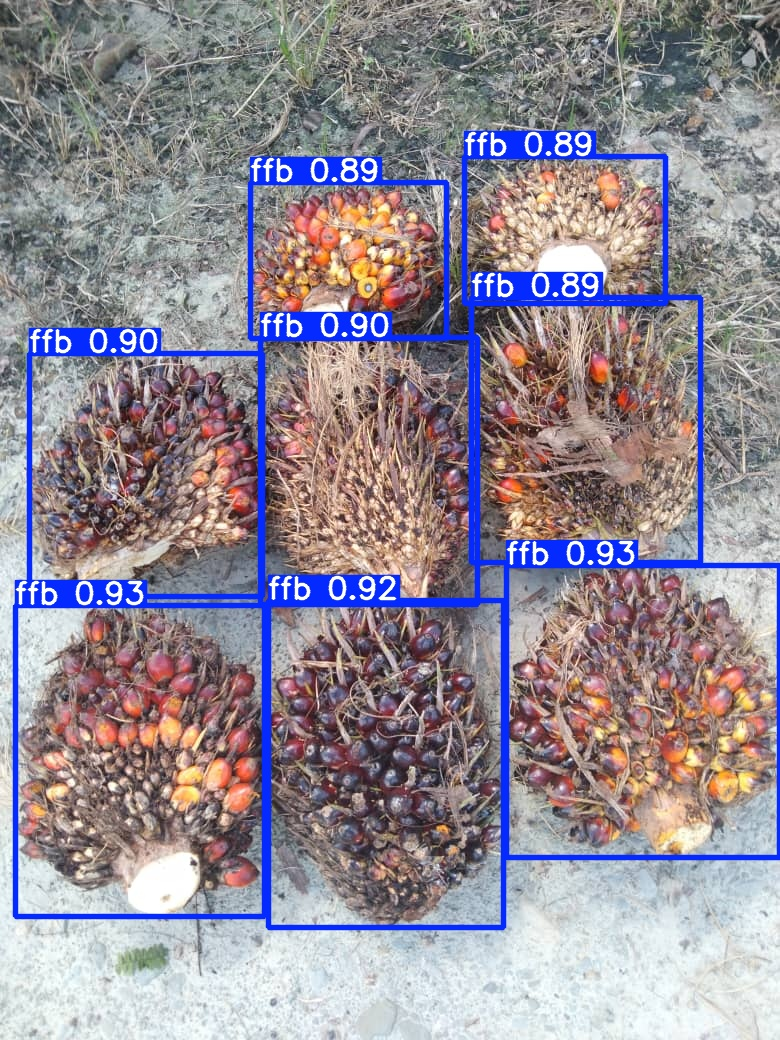

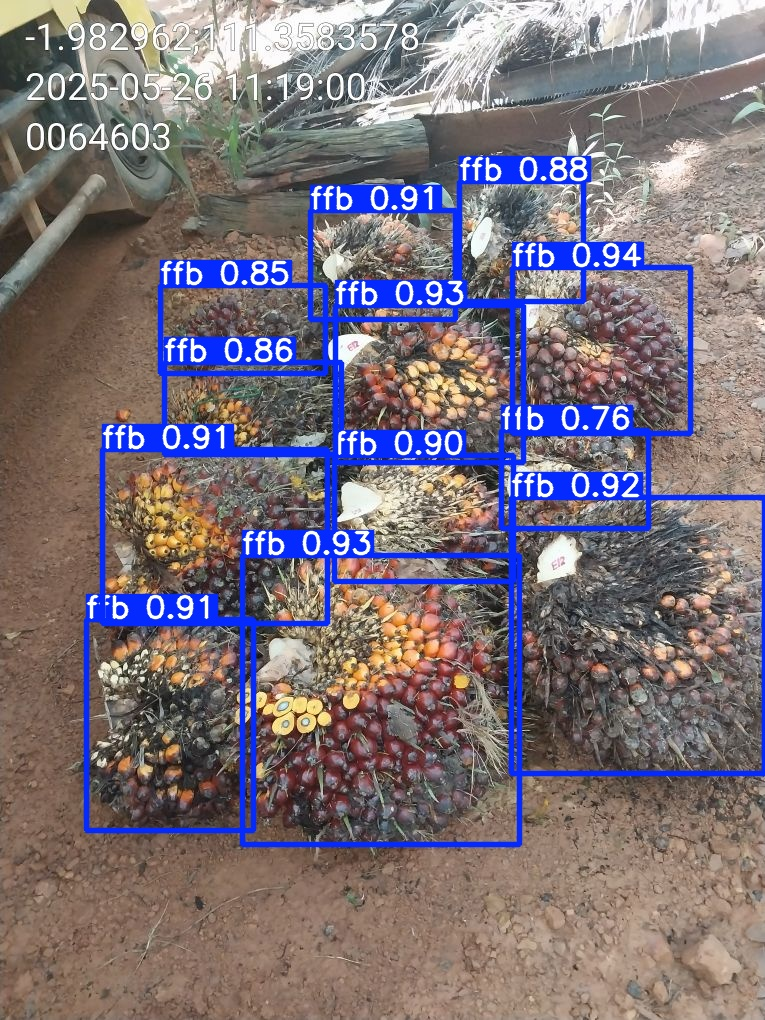

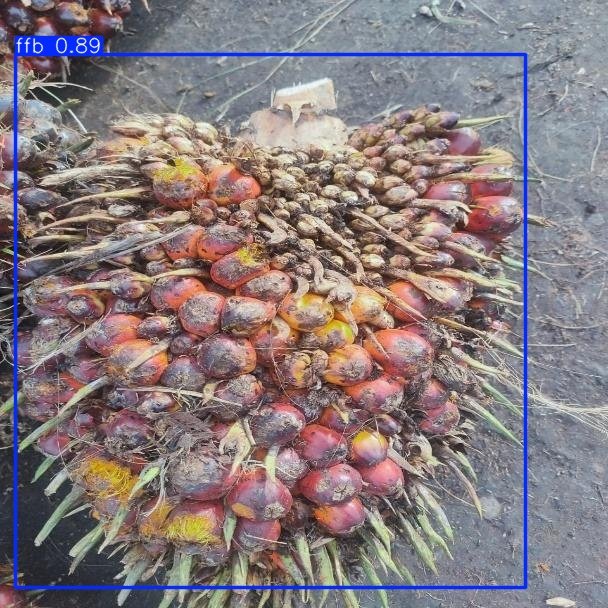

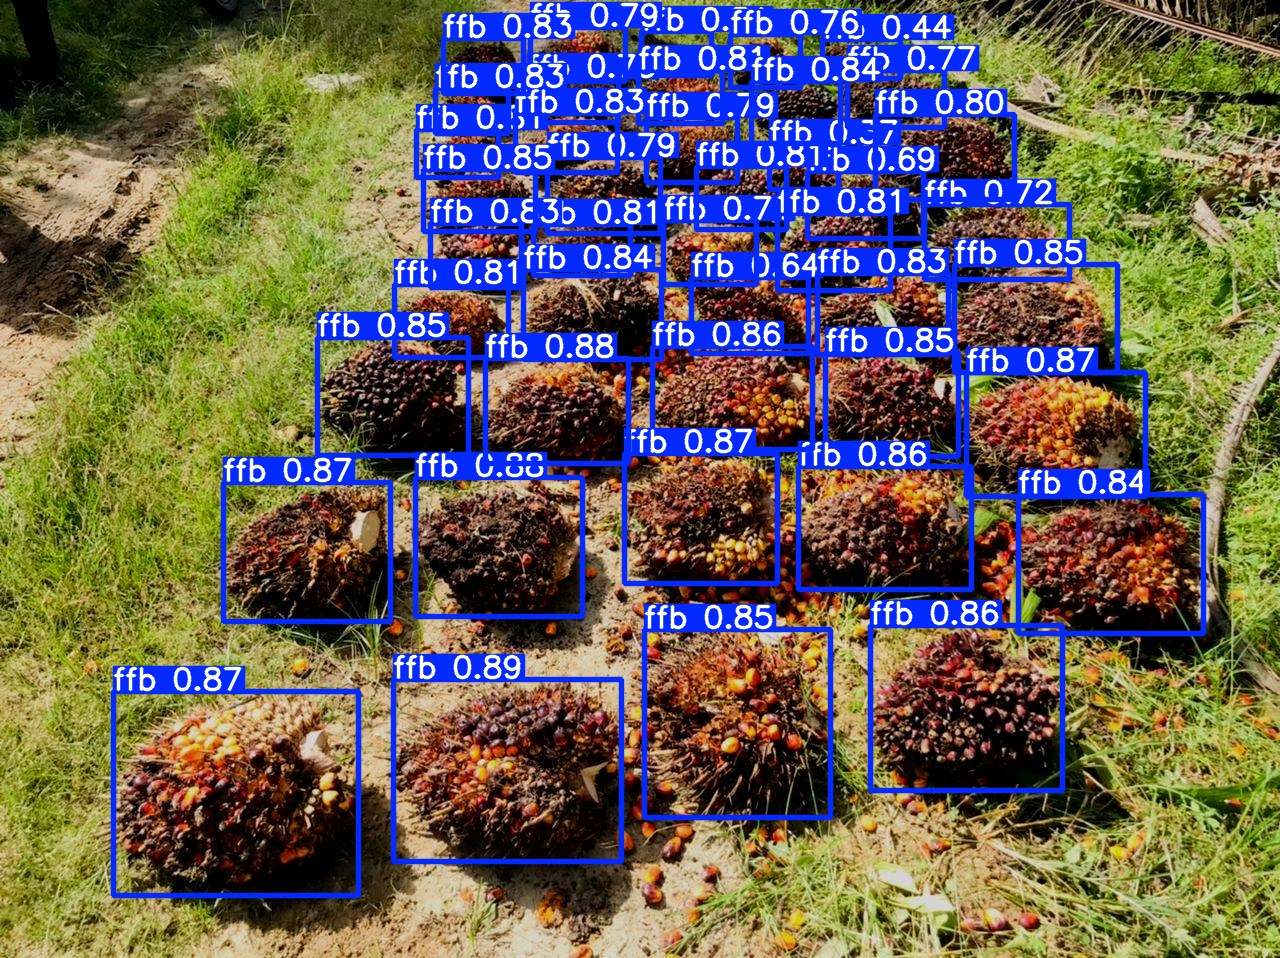

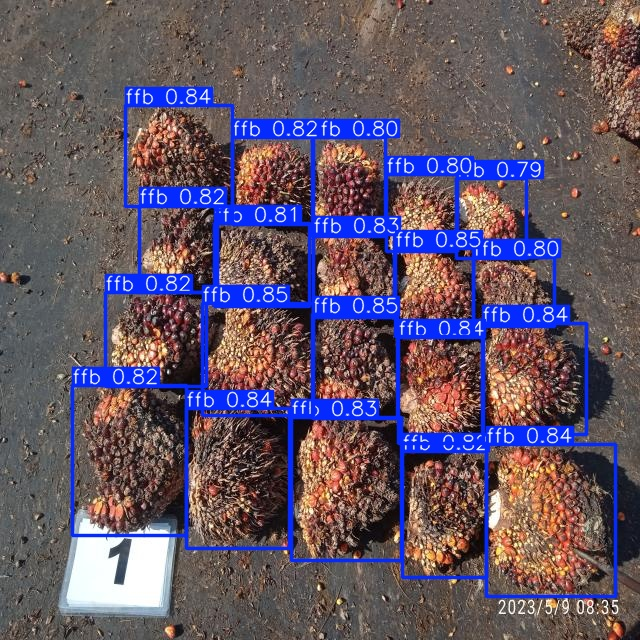

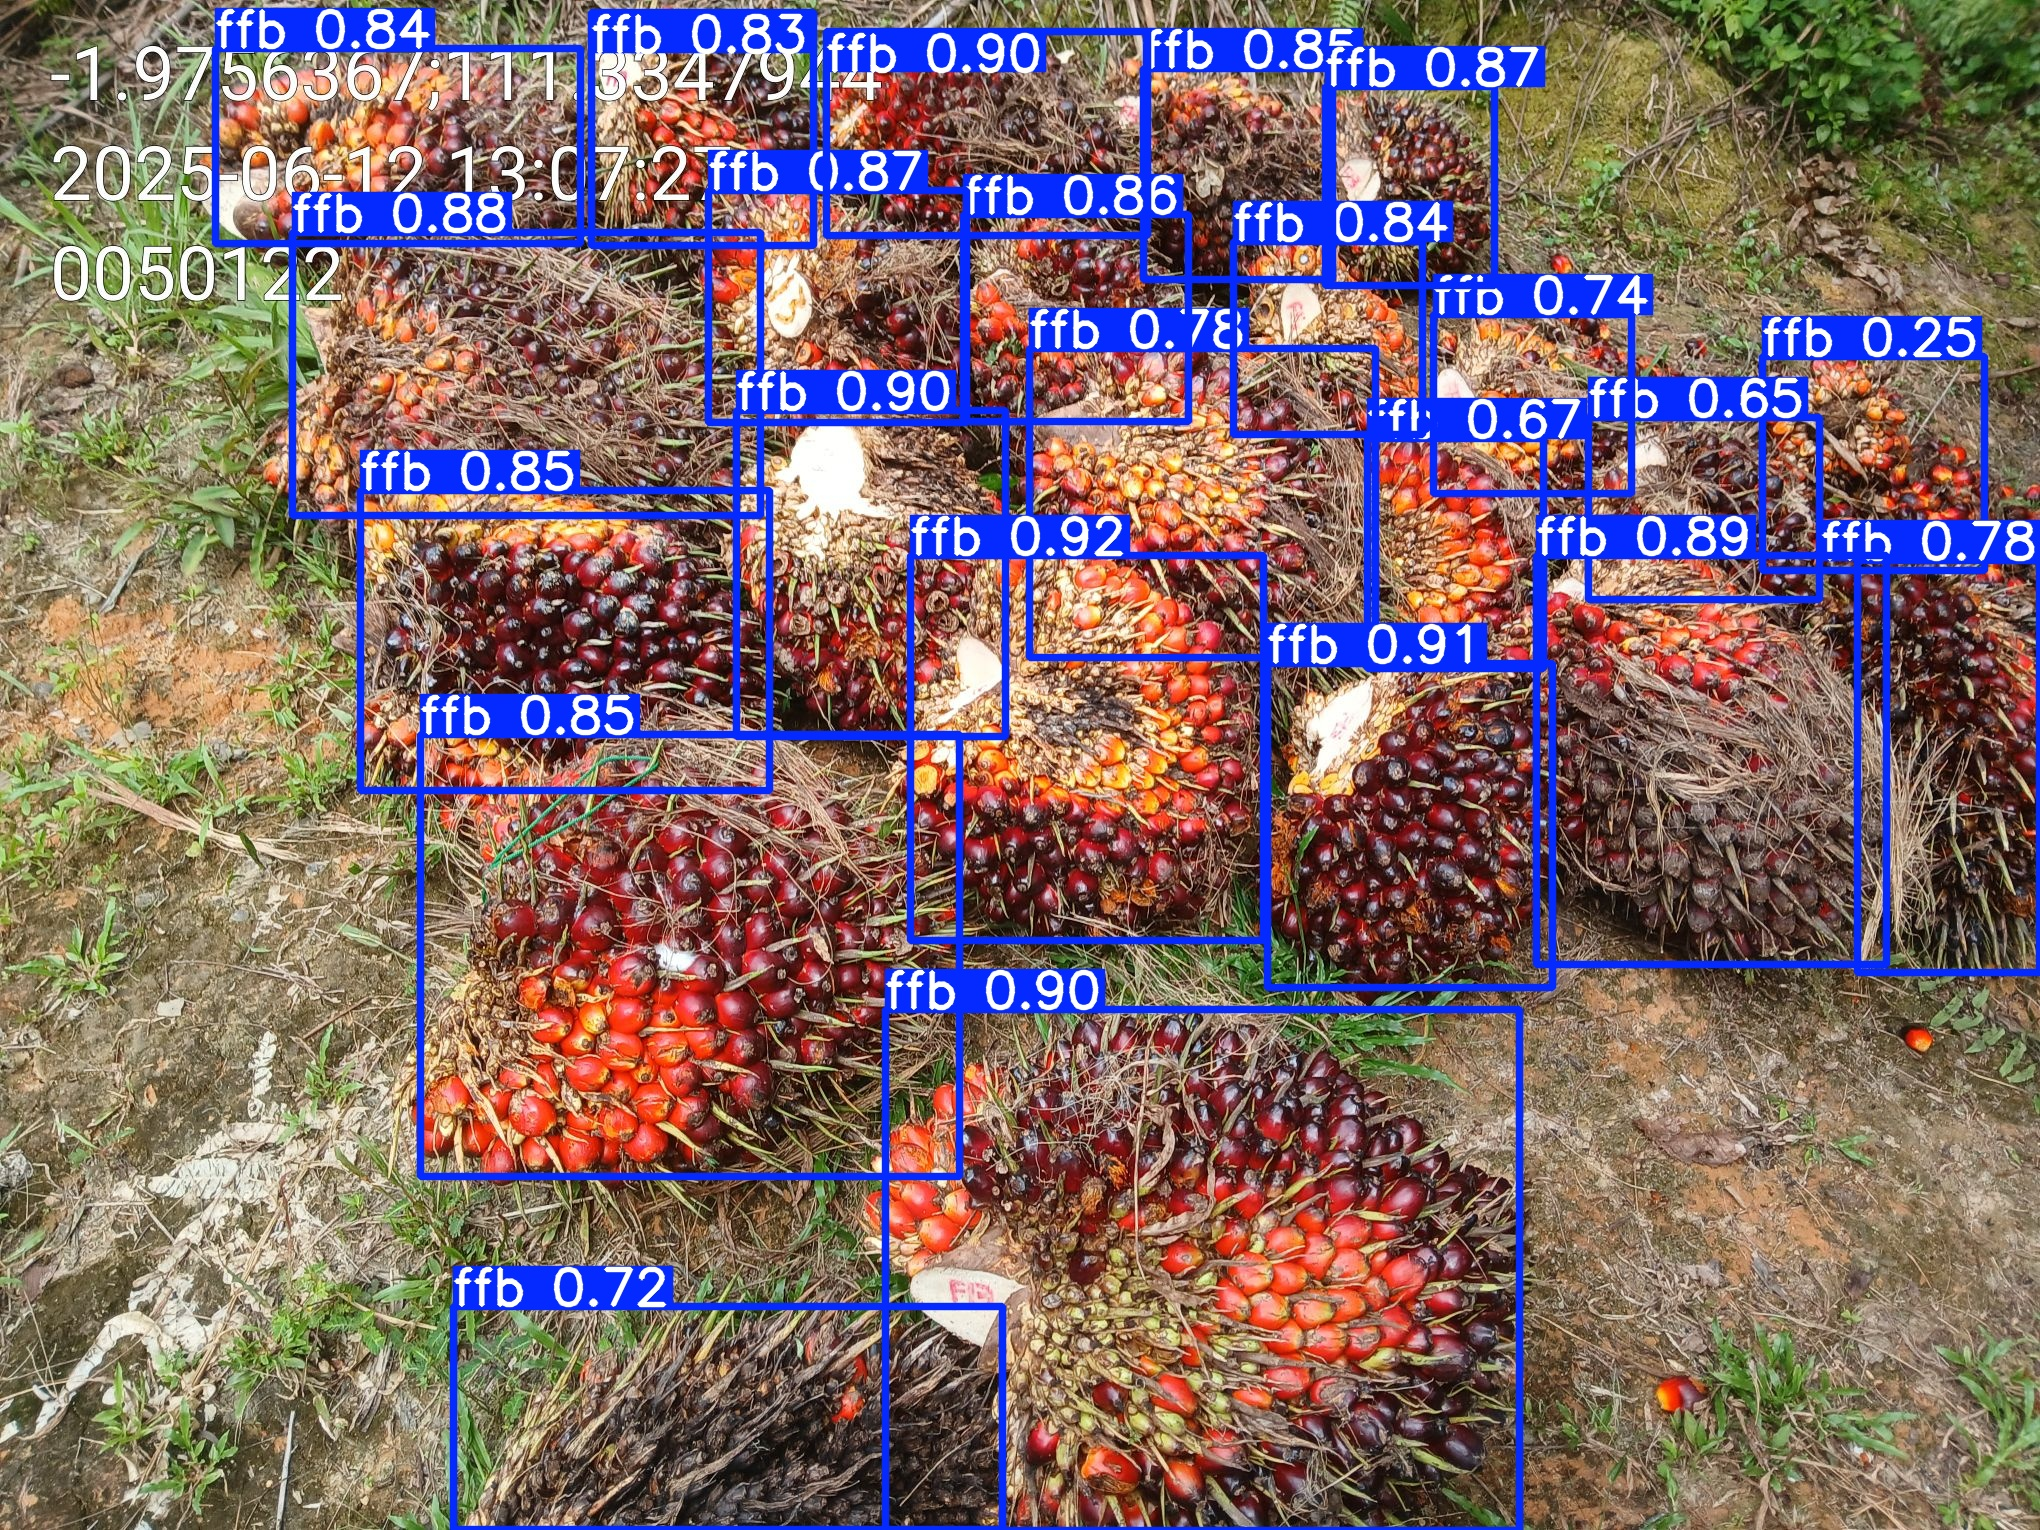

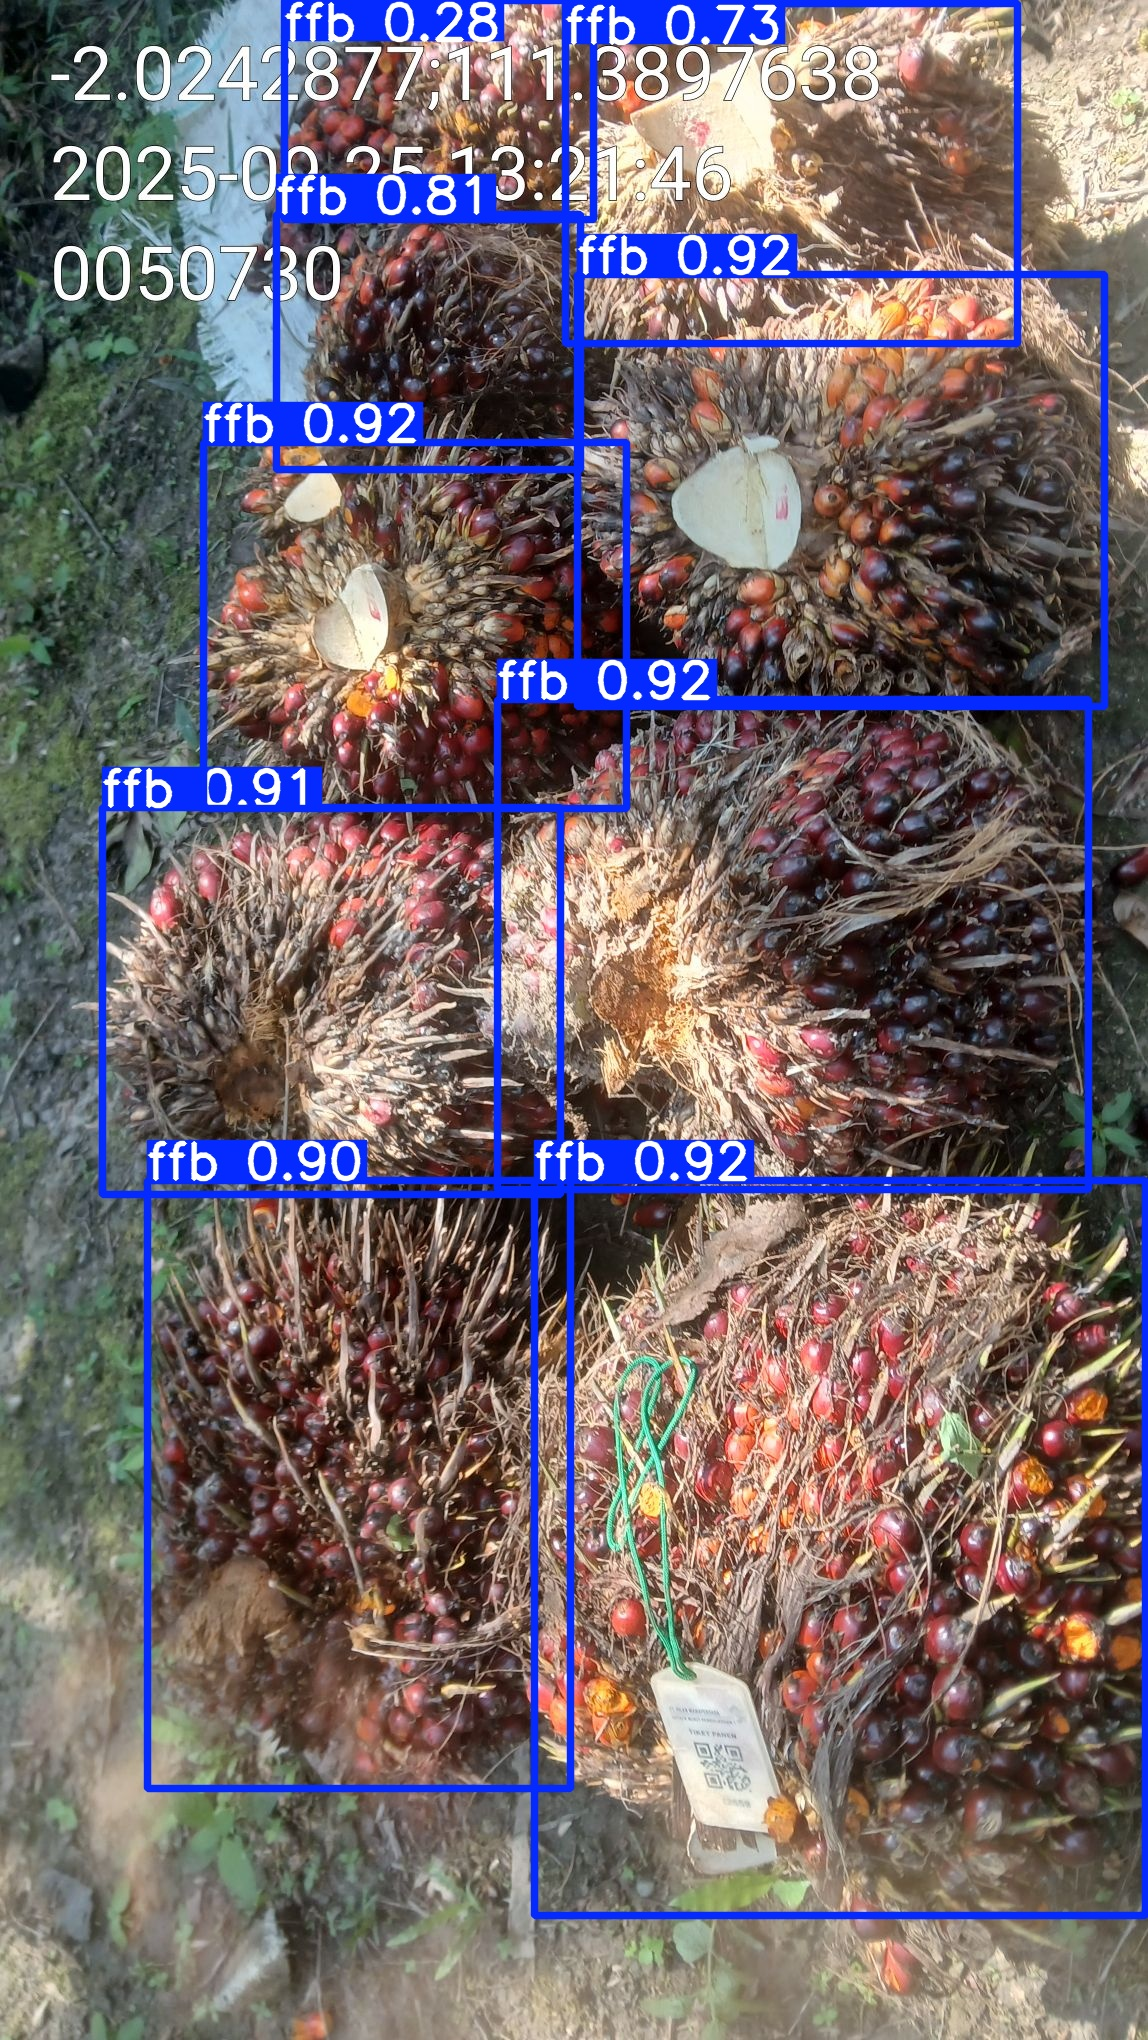

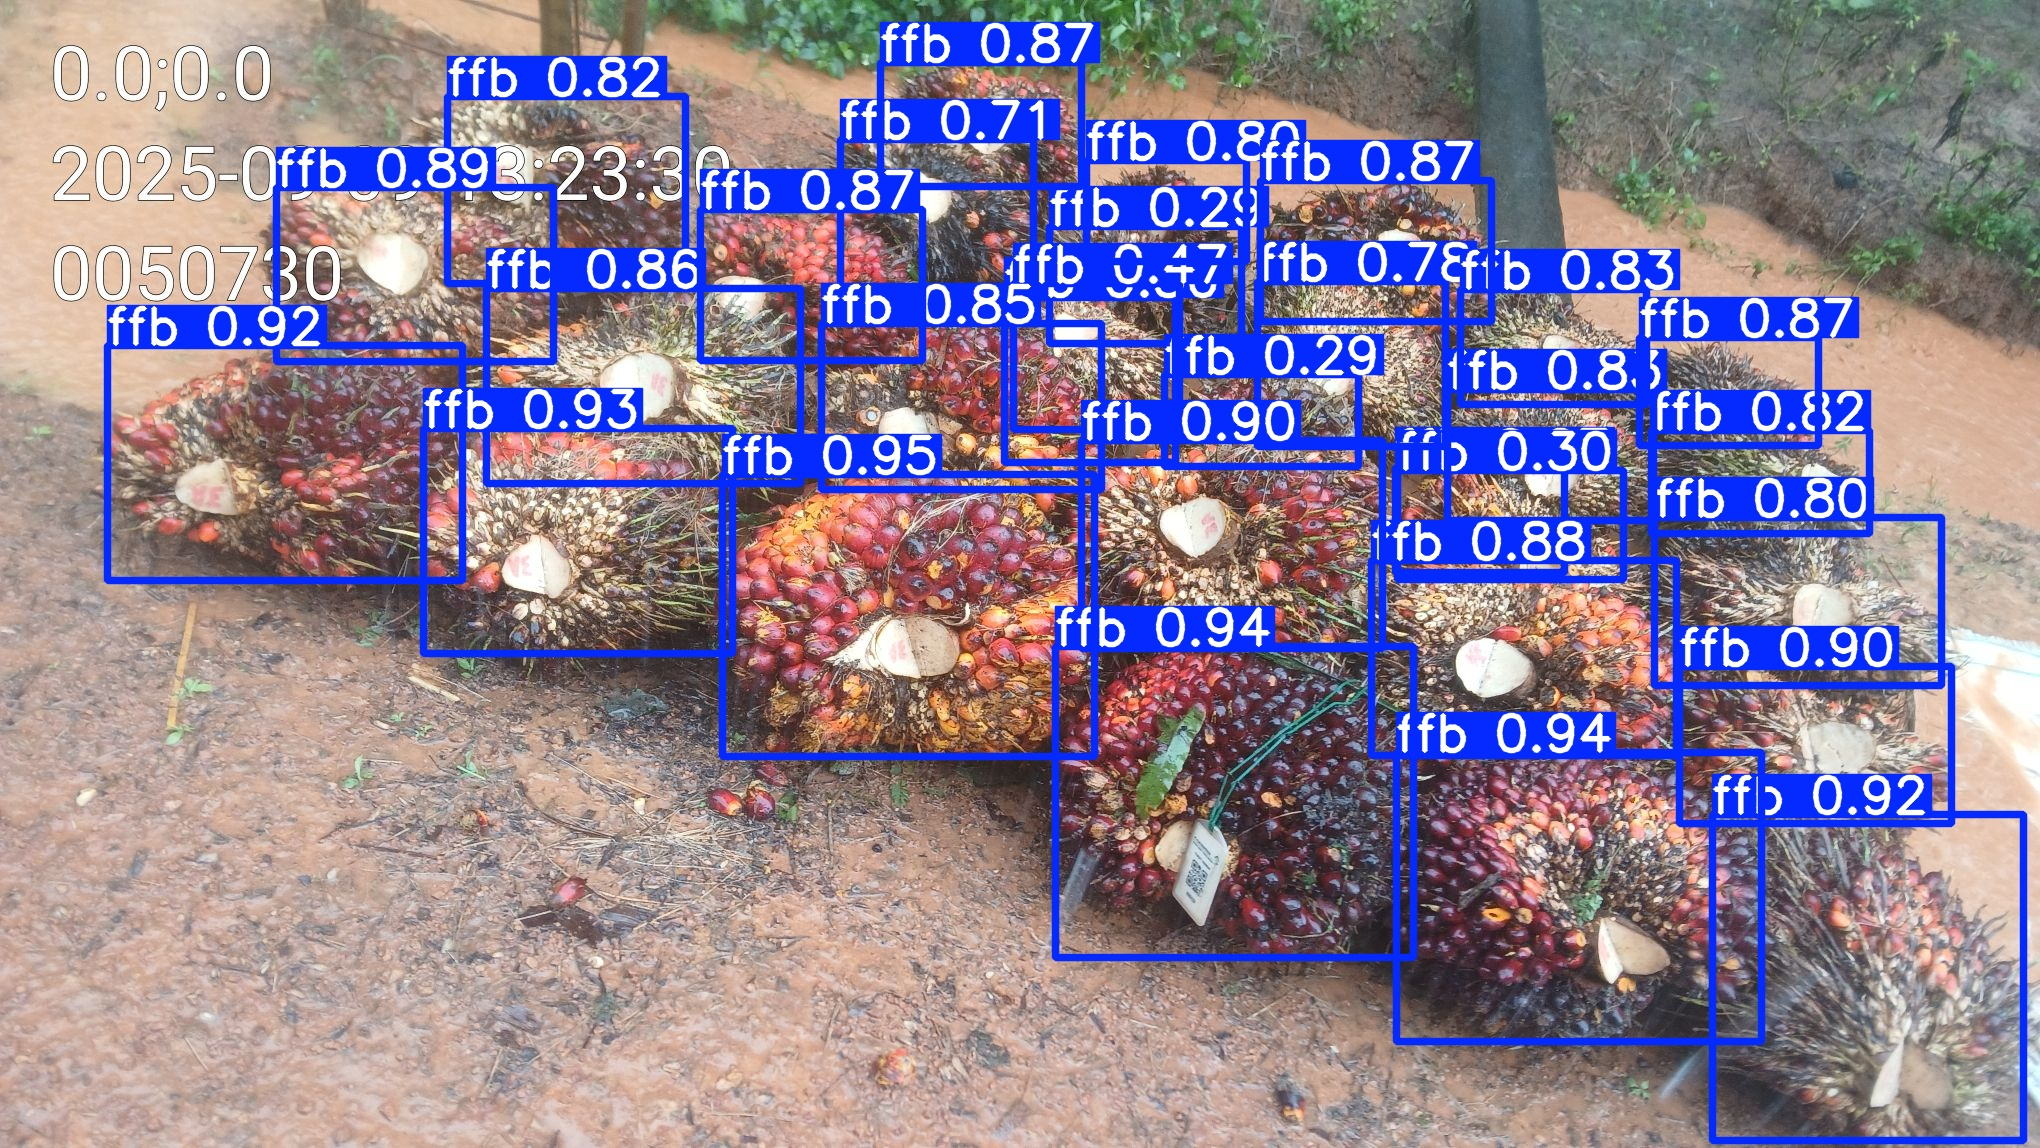

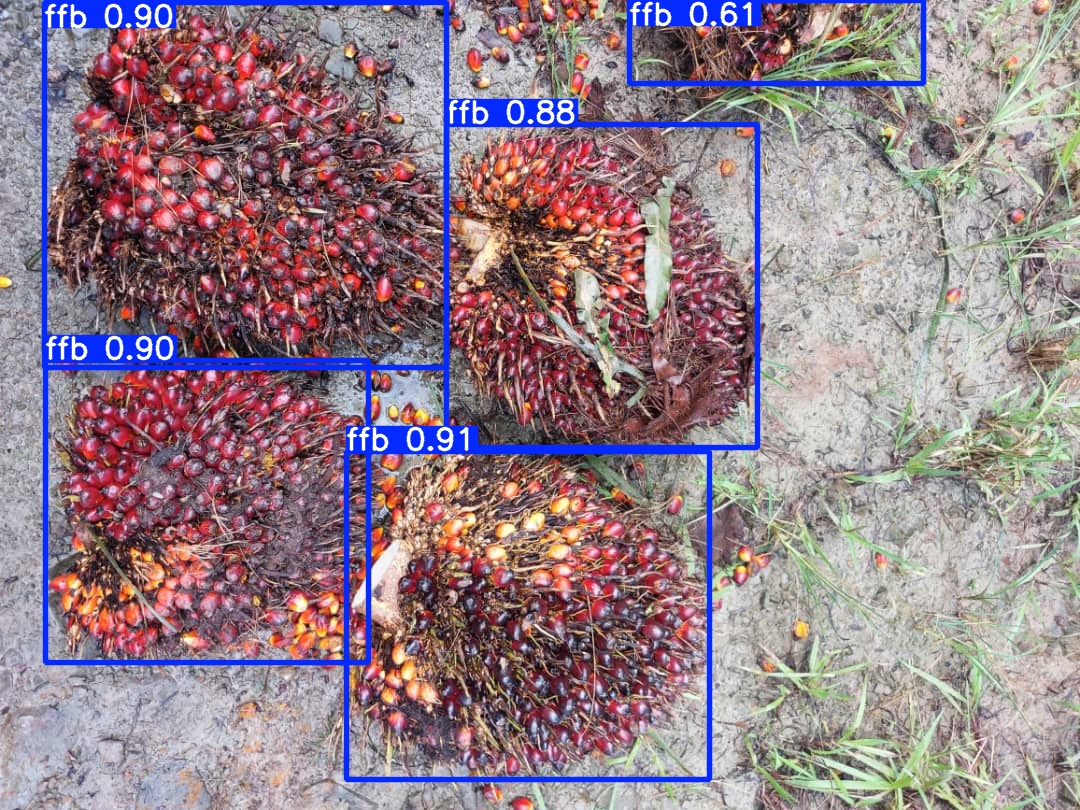

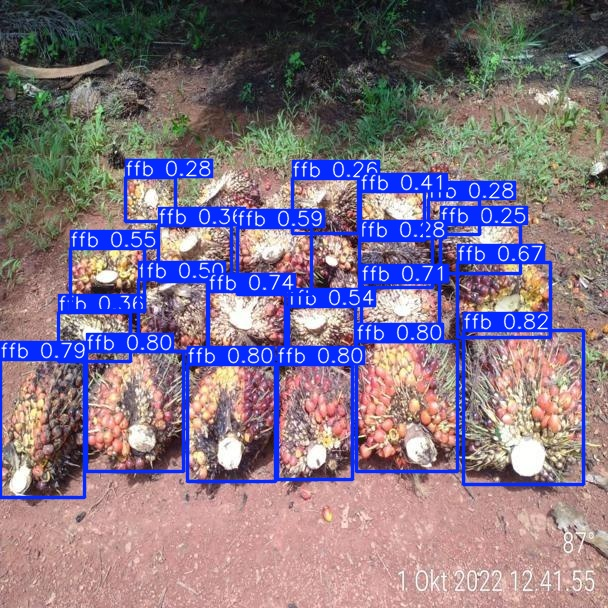

In [ ]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')


In [ ]:
import glob
import os

# Find the latest training run directory
list_of_runs = glob.glob('/content/runs/detect/train*')
print(f"Found potential run directories: {list_of_runs}")

if not list_of_runs:
    print("No training runs found in /content/runs/detect/. Please ensure training cell 5.2 has been executed successfully.")
else:
    # Sort by creation time to get the latest run
    latest_run_dir = max(list_of_runs, key=os.path.getctime)
    print(f"Using latest training run directory: {latest_run_dir}")

    # Define paths for the model and results
    best_model_path = os.path.join(latest_run_dir, 'weights', 'best.pt')
    train_results_path = latest_run_dir

    if not os.path.exists(best_model_path):
        print(f"Error: Best model weights not found at {best_model_path}. Ensure training completed successfully.")
    else:
        # Create "my_model" folder to store model weights and train results
        !mkdir -p /content/my_model # Use -p to avoid error if exists
        !cp {best_model_path} /content/my_model/my_model.pt
        !cp -r {train_results_path} /content/my_model/train_results # Copy results into a subfolder 'train_results' for clarity.

        # Zip into "my_model.zip"
        %cd /content/my_model
        !zip -r /content/my_model.zip . # Zip the current directory contents, which includes my_model.pt and train_results
        %cd /content
        print("Model packaged successfully into /content/my_model.zip")

Found potential run directories: ['/content/runs/detect/train']
Using latest training run directory: /content/runs/detect/train
/content/my_model
  adding: my_model.pt (deflated 8%)
  adding: train_results/ (stored 0%)
  adding: train_results/train_batch19602.jpg (deflated 4%)
  adding: train_results/val_batch0_labels.jpg (deflated 3%)
  adding: train_results/confusion_matrix.png (deflated 36%)
  adding: train_results/labels.jpg (deflated 33%)
  adding: train_results/val_batch1_labels.jpg (deflated 5%)
  adding: train_results/BoxR_curve.png (deflated 16%)
  adding: train_results/args.yaml (deflated 53%)
  adding: train_results/BoxF1_curve.png (deflated 15%)
  adding: train_results/BoxP_curve.png (deflated 21%)
  adding: train_results/val_batch2_pred.jpg (deflated 3%)
  adding: train_results/train_batch1.jpg (deflated 1%)
  adding: train_results/confusion_matrix_normalized.png (deflated 37%)
  adding: train_results/BoxPR_curve.png (deflated 25%)
  adding: train_results/val_batch1_pred.j

## 6.1 Old vs new: real bunches and "no bunch" photos

Runs on the validation images with the app's settings (confidence 0.18, IoU 0.5):
* **"No bunch" photos (`bg_…`)**: how many get any box. Lower is better; this is what the retraining fixes.
* **Bunch photos**: average count error against the labels. Must not get worse than the old model.
Upload the current model to Drive as `my_model_v1850.pt` to compare (optional).

In [ ]:
import glob, os
from ultralytics import YOLO

val_imgs = sorted(glob.glob('/content/data/validation/images/*'))
val_lbl = '/content/data/validation/labels'
bg  = [p for p in val_imgs if os.path.basename(p).startswith('bg_')]
pos = [p for p in val_imgs if not os.path.basename(p).startswith('bg_')]

def truth(p):
    f = os.path.join(val_lbl, os.path.splitext(os.path.basename(p))[0] + '.txt')
    return sum(1 for l in open(f) if l.strip()) if os.path.exists(f) else 0

def score(weights, imgsz):
    m = YOLO(weights)
    def counts(paths):
        out = []
        for i in range(0, len(paths), 32):
            for r in m.predict(paths[i:i+32], conf=0.18, iou=0.5, imgsz=imgsz, verbose=False):
                out.append(len(r.boxes))
        return out
    bc, pc = counts(bg), counts(pos)
    fp_imgs = sum(1 for c in bc if c > 0)
    err = sum(abs(c - truth(p)) for c, p in zip(pc, pos)) / max(len(pos), 1)
    return fp_imgs, sum(bc), err

print(f'Validation: {len(pos)} bunch photos, {len(bg)} "no bunch" photos\n')
rows = [('NEW', f'/content/my_model/my_model.pt', IMGSZ)]
if os.path.exists(OLD_MODEL_PT):
    rows.insert(0, ('OLD v1850', OLD_MODEL_PT, 640))
for name, w, sz in rows:
    fp, boxes, err = score(w, sz)
    print(f'{name:10s} | "no bunch" photos with a false box: {fp}/{len(bg)} ({boxes} boxes) '
          f'| bunch photos: avg count error {err:.2f}')

The model should draw a box around each object of interest in each image. If it isn't doing a good job of detecting objects, here are a few tips:

1. Double-check your dataset to make sure there are no labeling errors or conflicting examples.
2. Increase the number of epochs used for training.
3. Use a larger model size (e.g. `yolo11l.pt`).
4. Add more images to the training dataset. See my [dataset video](https://www.youtube.com/watch?v=v0ssiOY6cfg) for tips on how to capture good training images and improve accuracy.

You can also run the model on video files or other images images by uploading them to this notebook and using the above `!yolo detect predict` command, where `source` points to the location of the video file, image, or folder of images. The results will be saved in `runs/detect/predict`.

Drawing boxes on images is great, but it isn't very useful in itself. It's also not very helpful to just run this models inside a Colab notebook: it's easier if we can just run it on a local computer. Continue to the next section to see how to download your newly trained model and run it on a local device.

#7.&nbsp;Deploy Model

Now that your custom model has been trained, it's ready to be downloaded and deployed in an application! YOLO models can run on a wide variety of hardware, including PCs, embedded systems, and phones. Ultralytics makes it easy to convert the YOLO models to various formats (`tflite`, `onnx`, etc.) and deploy them in a variety of environments.

This section shows how to download the model and provides links to instructions for deploying it on your PC and edge devices like the Raspberry Pi.

## 7.1 Download YOLO Model

First, zip and download the trained model by running the code blocks below.

The code creates a folder named `my_model`, moves the model weights into it, and renames them from `best.pt` to `my_model.pt`. It also adds the training results in case you want to reference them later. It then zips the folder as `my_model.zip`.

In [ ]:
import glob, os, shutil, subprocess

# Find the latest training run directory
list_of_runs = glob.glob('/content/runs/detect/train*')
print(f'Found run directories: {list_of_runs}')

if not list_of_runs:
    print('❌ No training runs found in /content/runs/detect/ — run training first (Section 5).')
else:
    latest_run_dir = max(list_of_runs, key=os.path.getctime)
    print(f'Using: {latest_run_dir}')
    best_model_path = os.path.join(latest_run_dir, 'weights', 'best.pt')

    if not os.path.exists(best_model_path):
        print(f'❌ Best model weights not found at {best_model_path} — did training finish?')
    else:
        # Package into my_model/
        shutil.rmtree('/content/my_model', ignore_errors=True)
        os.makedirs('/content/my_model', exist_ok=True)
        shutil.copy(best_model_path, '/content/my_model/my_model.pt')
        shutil.copytree(latest_run_dir, '/content/my_model/train_results')

        # Zip it
        if os.path.exists('/content/my_model.zip'):
            os.remove('/content/my_model.zip')
        subprocess.run(['zip', '-r', '/content/my_model.zip', '.'],
                       cwd='/content/my_model', check=True)
        print(f'✅ Model packaged → /content/my_model.zip')

        # Also save best.pt directly to Drive for quick access
        if os.path.isdir('/content/gdrive/MyDrive'):
            drive_out = f'/content/gdrive/MyDrive/my_model_{IMGSZ}.pt'
            shutil.copy(best_model_path, drive_out)
            print(f'✅ Also saved to Drive: {drive_out}')


mkdir: cannot create directory ‘/content/my_model’: File exists
/content/my_model
updating: my_model.pt (deflated 8%)
  adding: train/ (stored 0%)
  adding: train/train_batch19602.jpg (deflated 4%)
  adding: train/val_batch0_labels.jpg (deflated 3%)
  adding: train/confusion_matrix.png (deflated 36%)
  adding: train/labels.jpg (deflated 33%)
  adding: train/val_batch1_labels.jpg (deflated 5%)
  adding: train/BoxR_curve.png (deflated 16%)
  adding: train/args.yaml (deflated 53%)
  adding: train/BoxF1_curve.png (deflated 15%)
  adding: train/BoxP_curve.png (deflated 21%)
  adding: train/val_batch2_pred.jpg (deflated 3%)
  adding: train/train_batch1.jpg (deflated 1%)
  adding: train/confusion_matrix_normalized.png (deflated 37%)
  adding: train/BoxPR_curve.png (deflated 25%)
  adding: train/val_batch1_pred.jpg (deflated 4%)
  adding: train/val_batch2_labels.jpg (deflated 3%)
  adding: train/results.png (deflated 8%)
  adding: train/train_batch19600.jpg (deflated 5%)
  adding: train/weight

In [ ]:
# This takes forever for some reason, you can also just download the model from the sidebar
from google.colab import files

files.download('/content/my_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7.2 Deploy YOLO Model on Local Devices

Next, we'll take our downloaded model and run it on a local device. This section provides instructions showing how to deploy YOLO models on various devices.

I wrote a basic Python script, `yolo_detect.py`, that shows how to load a model, run inference on an image source, parse the inference results, and display boxes around each detected class in the image. The [script](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/blob/main/yolo_detect.py) gives an example of how to work with Ultralytics YOLO models in Python, and it can be used as a starting point for more advanced applications.

### 7.2.1 Deploy on PC (Windows, Linux, or macOS)

The easiest way to run Ultralytics models on a PC is using Anaconda. Anaconda sets up a virtual Python environment and allows you to easily install Ultralytics and PyTorch. It automatically installs CUDA and cuDNN, which allows you to speed up model inference with your NVIDIA GPU.

> **NOTE:** My YouTube video (link to be added) shows how to deploy your model on a PC. It walks through the following steps, so watch the video if you prefer having visual instructions.

**1. Download and Install Anaconda**

Go to the Anaconda download page at https://anaconda.com/download, click the “skip registration” button, and then download the package for your OS. When it's finished downloading, run the installer and click through the installation steps. You can use the default options for installation.

**2. Set up virtual environment**

Once it's installed, run Anaconda Prompt from the Start Bar. (If you're on macOS or Linux, just open a command terminal).

Issue the following commands to create a new Python environment and activate it:

```
conda create --name yolo-env1 python=3.12 -y
conda activate yolo-env1
```

Install Ultralytics (which also installs import libraries like OpenCV-Python, Numpy, and PyTorch) by issuing the following command:

```
pip install ultralytics
```

If you have an NVIDIA GPU, you can install the GPU-enabled version of PyTorch by issuing the following command:

```
pip install --upgrade torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124
```

**3. Extract downloaded model**
Take the `my_model.zip` file you downloaded in Step 7.1 and unzip it to a folder on your PC. In the Anaconda Prompt terminal, move into the unzipped folder using:

```
cd path/to/folder
```

**4. Download and run yolo_detect.py**

Download the `yolo_detect.py` script into the `my_model` folder using:

```
curl -o yolo_detect.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/yolo_detect.py
```

Alright! We're ready to run the script. To run inference with a yolov8s model on a USB camera at 1280x720 resolution, issue:

```
python yolo_detect.py --model my_model.pt --source usb0 --resolution 1280x720
```

A window will appear showing a live feed from your webcam with boxes drawn around detected objects in each frame.

You can also run the model on an video file, image, or folder of images. To see a full list of arguments for `yolo_detect.py`, issue `python yolo_detect.py --help` or see the [README file](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/blob/main/README.md).




### 7.2.2 Deploy on Android Application


To export your YOLO model (such as YOLOv8, YOLOv9, or YOLOv11) to a lightweight TensorFlow Lite (TFLite) format for Android deployment, use the export() method from the Ultralytics library


In [ ]:
from ultralytics import YOLO
import glob, os, shutil

model_path = '/content/my_model/my_model.pt'
if not os.path.exists(model_path):
    print(f"Error: Model not found at {model_path}. Run the packaging step (7.1) first.")
else:
    model = YOLO(model_path)
    # int8 is what the app uses (assets/my_model_int8.tflite). data= gives calibration images.
    model.export(format='tflite', int8=True, imgsz=IMGSZ, data='/content/data.yaml')
    found = sorted(glob.glob('/content/my_model/**/*int8*.tflite', recursive=True))
    print('Exported:', found)
    if found:
        out = f'/content/my_model/my_model_{IMGSZ}_int8.tflite'
        shutil.copy(found[0], out)
        shutil.copy(out, f'/content/gdrive/MyDrive/my_model_{IMGSZ}_int8.tflite')
        print(f'Saved {out} and a copy on Drive. Put it in the app as assets/my_model_int8.tflite')

In [ ]:

# Load the custom trained model (if not already loaded)
# model = YOLO('/content/runs/detect/train/weights/best.pt')

# Directory where predicted images are saved
prediction_output_dir = '/content/runs/detect/predict'

print(f"\nCounting FFB in images located in: {prediction_output_dir}")

# Iterate through each predicted image and count FFB
for image_path in glob.glob(f'{prediction_output_dir}/*.jpg'):
    results = model.predict(source=image_path, save=False, conf=0.25)
    ffb_count = 0
    for r in results:
        class_names = r.names
        for c in r.boxes.cls:
            if class_names[int(c)] == 'ffb':
                ffb_count += 1
    print(f"Detected {ffb_count} FFB in {os.path.basename(image_path)}")


Counting FFB in images located in: /content/runs/detect/predict


NameError: name 'model' is not defined

### Debugging False Positives
If the model is detecting your hand or face, we can check the 'Confidence Score'. If the false detections have low confidence (e.g., 0.3), we can set a higher threshold during prediction.

In [ ]:
# Run prediction again but show the confidence scores
# This helps determine if we can just filter out the noise
results = model.predict(source='/content/data/validation/images', conf=0.25)

for r in results:
    for box in r.boxes:
        conf = box.conf[0]
        cls = int(box.cls[0])
        if conf > 0.20:
            print(f"Detected {model.names[cls]} with {conf:.2f} confidence")

In [ ]:
from google.colab import files
import os
from IPython.display import Image, display

# Upload the image
print("Please upload your image file:")
uploaded = files.upload()

# Get the filename of the uploaded image
for fn in uploaded.keys():
    uploaded_image_path = os.path.join('/content', fn)
    print(f'User uploaded file "{fn}" at {uploaded_image_path}')

    # Run prediction on the uploaded image
    # The model path should be updated if you've renamed or moved it
    !yolo detect predict model=runs/detect/train/weights/best.pt source={uploaded_image_path} save=True

    # Display the result (assuming it's saved in the 'predict' folder under a new run)
    # We need to find the latest prediction run directory
    import glob
    list_of_predict_runs = glob.glob('/content/runs/detect/predict*')
    if list_of_predict_runs:
        latest_predict_run = max(list_of_predict_runs, key=os.path.getctime)
        predicted_image_name = os.path.basename(uploaded_image_path) # Original image name
        predicted_image_output_path = os.path.join(latest_predict_run, predicted_image_name)

        print(f"\nDisplaying prediction for {predicted_image_name}:")
        if os.path.exists(predicted_image_output_path):
            display(Image(filename=predicted_image_output_path, height=400))
        else:
            print(f"Predicted image not found at {predicted_image_output_path}. Check the output directory for the prediction run.")
    else:
        print("No prediction runs found. Ensure the prediction command executed successfully.")



# 8.&nbsp;Conclusion

Congratulations! You've successfully trained and deployed a YOLO object detection model. 😀

Next, you can extend your application beyond just drawing boxes and counting objects. Add functionality like logging the number of objects detected over time or taking a picture when certain objects are detected. Check out some example applications at our GitHub repository: https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models

Thanks for working through this notebook, and good luck with your projects!

# Appendix: Common Errors

If you run into any errors working through this notebook, please do the following:


- Double-check that the dataset files are set up in the correct folder structure
- Make sure there are no typos or errors in your labelmap file
- Google search the error to look for solutions

If none of those help, please submit an [Issue](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/issues) on the GitHub page. In this section, I will add resolutions to common errors as they come up.